# Opgave 1

## 1A

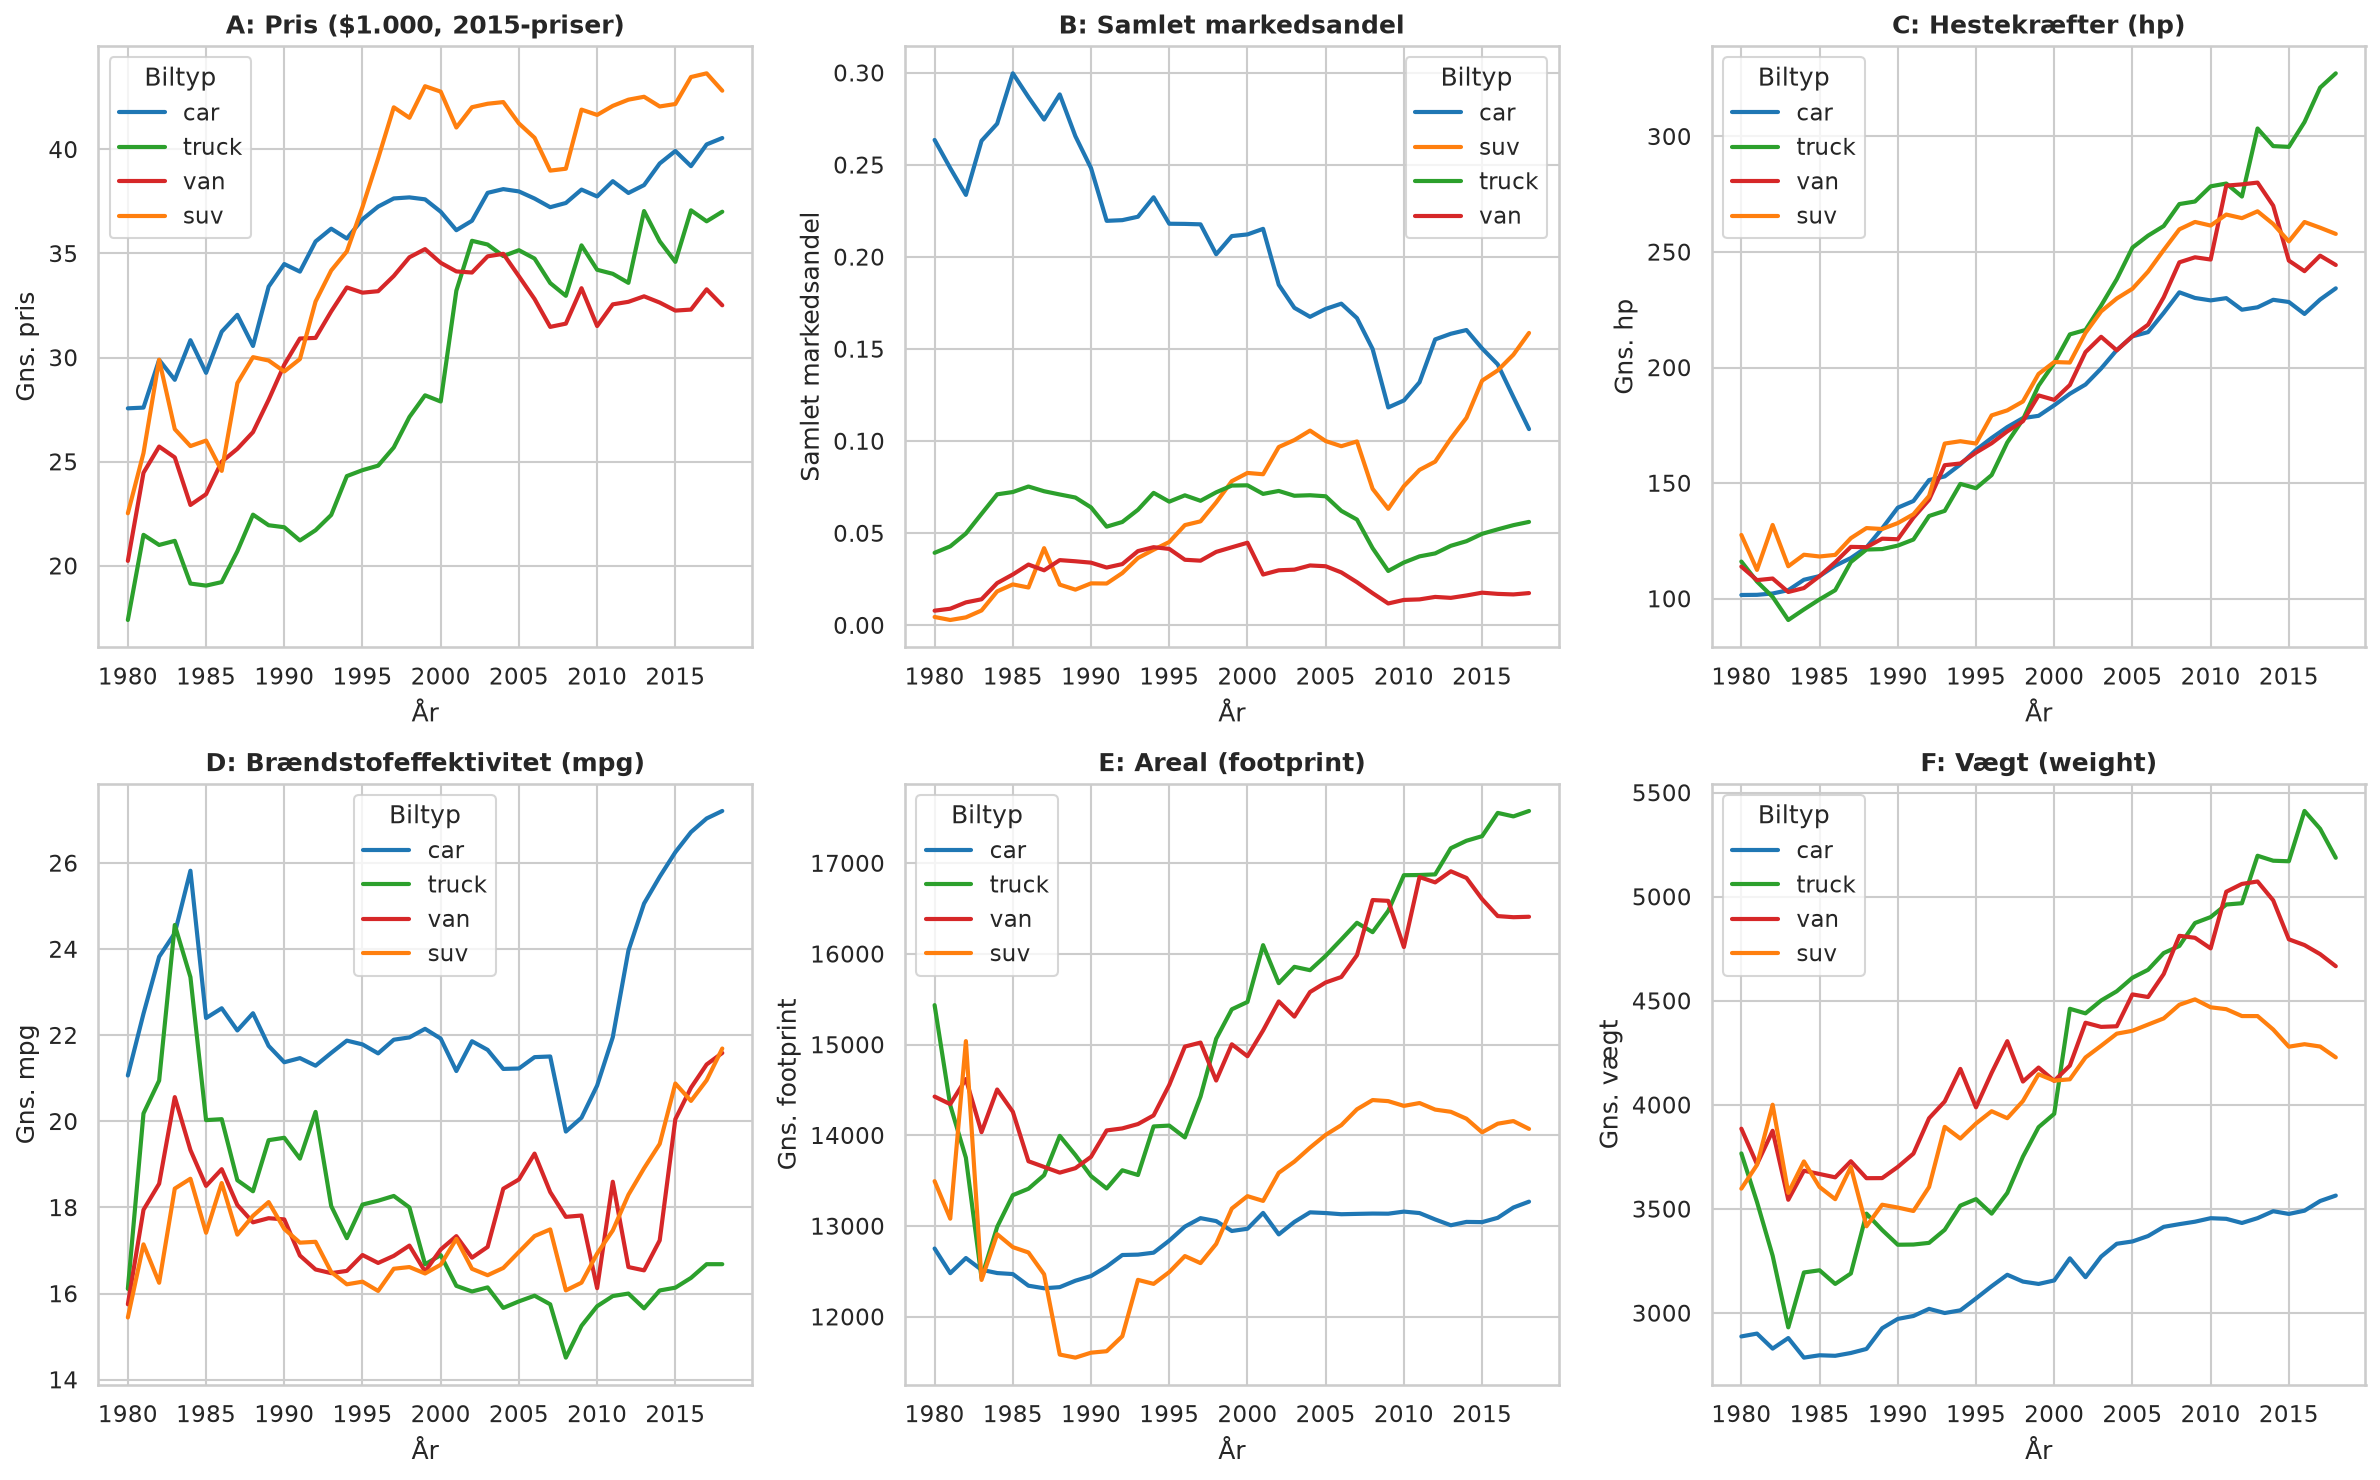

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cars.csv')

type_cols = ['car', 'suv', 'truck', 'van']

def get_body_type(row):
    for c in type_cols:
        if row[c] == 1:
            return c
    return 'other'

df['body_type'] = df.apply(get_body_type, axis=1)

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

palette = {'car': '#1f77b4', 'suv': '#ff7f0e', 'truck': '#2ca02c', 'van': '#d62728'}

sns.lineplot(data=df, x='year', y='price', hue='body_type',
             palette=palette, ax=axes[0, 0], errorbar=None, linewidth=2)
axes[0, 0].set_title('A: Pris ($1.000, 2015-priser)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('År')
axes[0, 0].set_ylabel('Gns. pris')
axes[0, 0].legend(title='Biltyp')

ms_time = df.groupby(['year', 'body_type'])['market_share'].sum().reset_index()
sns.lineplot(data=ms_time, x='year', y='market_share', hue='body_type', palette=palette, ax=axes[0, 1], linewidth=2)
axes[0, 1].set_title('B: Samlet markedsandel', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('År')
axes[0, 1].set_ylabel('Samlet markedsandel')
axes[0, 1].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='hp', hue='body_type',
             palette=palette, ax=axes[0, 2], errorbar=None, linewidth=2)
axes[0, 2].set_title('C: Hestekræfter (hp)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('År')
axes[0, 2].set_ylabel('Gns. hp')
axes[0, 2].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='mpg', hue='body_type',
             palette=palette, ax=axes[1, 0], errorbar=None, linewidth=2)
axes[1, 0].set_title('D: Brændstofeffektivitet (mpg)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('År')
axes[1, 0].set_ylabel('Gns. mpg')
axes[1, 0].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='footprint', hue='body_type',
             palette=palette, ax=axes[1, 1], errorbar=None, linewidth=2)
axes[1, 1].set_title('E: Areal (footprint)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('År')
axes[1, 1].set_ylabel('Gns. footprint')
axes[1, 1].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='weight', hue='body_type',
             palette=palette, ax=axes[1, 2], errorbar=None, linewidth=2)
axes[1, 2].set_title('F: Vægt (weight)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('År')
axes[1, 2].set_ylabel('Gns. vægt')
axes[1, 2].legend(title='Biltyp')

plt.tight_layout()


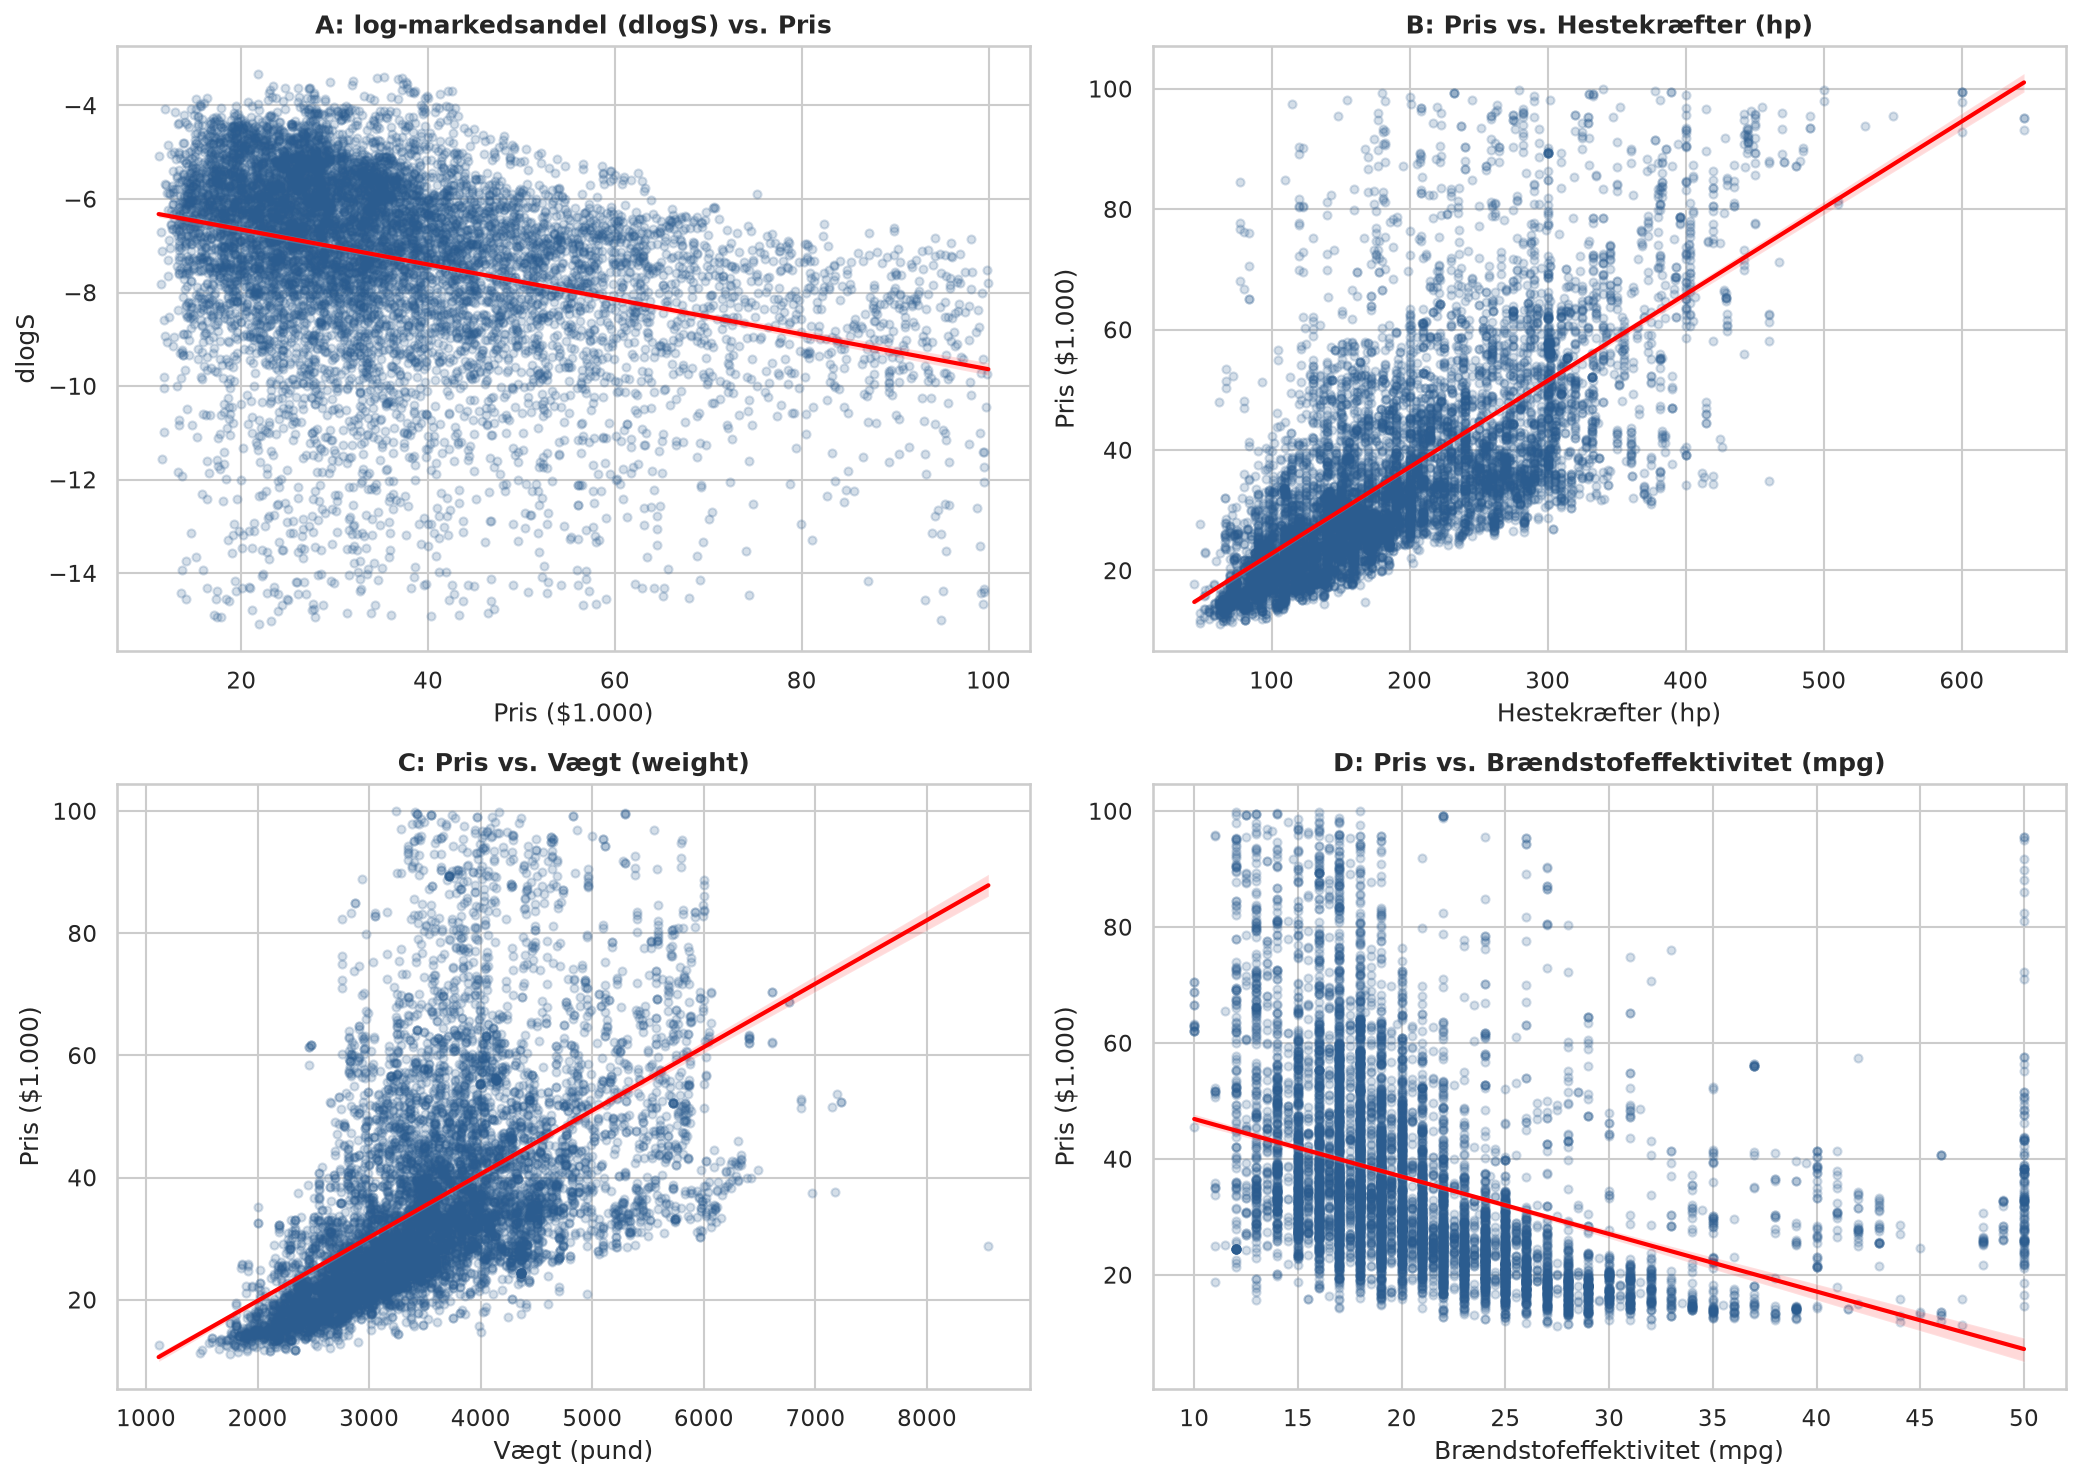

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.regplot(data=df, x='price', y='dlogS', ax=axes[0, 0], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[0, 0].set_title('A: log-markedsandel (dlogS) vs. Pris', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Pris ($1.000)')
axes[0, 0].set_ylabel('dlogS')

sns.regplot(data=df, x='hp', y='price', ax=axes[0, 1], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[0, 1].set_title('B: Pris vs. Hestekræfter (hp)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Hestekræfter (hp)')
axes[0, 1].set_ylabel('Pris ($1.000)')

sns.regplot(data=df, x='weight', y='price', ax=axes[1, 0], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[1, 0].set_title('C: Pris vs. Vægt (weight)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Vægt (pund)')
axes[1, 0].set_ylabel('Pris ($1.000)')

sns.regplot(data=df, x='mpg', y='price', ax=axes[1, 1], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[1, 1].set_title('D: Pris vs. Brændstofeffektivitet (mpg)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Brændstofeffektivitet (mpg)')
axes[1, 1].set_ylabel('Pris ($1.000)')

plt.tight_layout()

## 1B

In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

df = pd.read_csv('cars.csv')

y = df['dlogS']

X1 = sm.add_constant(df['price'])
model1 = sm.OLS(y, X1).fit()

chars2 = ['hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']
X2 = sm.add_constant(df[['price'] + chars2])
model2 = sm.OLS(y, X2).fit()

year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
X3 = pd.concat([X2, year_dummies], axis=1)
model3 = sm.OLS(y, X3).fit()

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

chars4 = ['log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']
X4 = sm.add_constant(df[['price'] + chars4])
X4 = pd.concat([X4, year_dummies], axis=1)
model4 = sm.OLS(y, X4).fit()

def print_model_summary(model, name):
    rss = model.ssr
    ess = model.ess
    tss = model.centered_tss
    r2 = model.rsquared
    print(f"\n================ {name} ================")
    print(f"R-squared: {r2:.6f}")
    print(f"TSS: {tss:.4f}")
    print(f"ESS: {ess:.4f}")
    print(f"RSS: {rss:.4f}")
    print("\nCoefficients:")
    params = model.params
    bse = model.bse
    tvals = model.tvalues
    pvals = model.pvalues
    
    summary_df = pd.DataFrame({
        'Coef': params,
        'Std.Err': bse,
        't-stat': tvals,
        'p-val': pvals
    })
    
    non_year = [c for c in summary_df.index if not c.startswith('y_')]
    print(summary_df.loc[non_year].round(6))

print_model_summary(model1, "Specifikation 1")
print_model_summary(model2, "Specifikation 2")
print_model_summary(model3, "Specifikation 3")
print_model_summary(model4, "Specifikation 4")


================ Specifikation 1 ================
R-squared: 0.106197
TSS: 37300.6952
ESS: 3961.2203
RSS: 33339.4749

Coefficients:
           Coef   Std.Err      t-stat  p-val
const -5.907219  0.043898 -134.567253    0.0
price -0.037326  0.001100  -33.934529    0.0

================ Specifikation 2 ================
R-squared: 0.300057
TSS: 37300.6952
ESS: 11192.3322
RSS: 26108.3630

Coefficients:
                      Coef   Std.Err     t-stat     p-val
const            -5.413798  0.290803 -18.616711  0.000000
price            -0.024260  0.001611 -15.056687  0.000000
hp               -0.003792  0.000372 -10.184646  0.000000
mpg              -0.042658  0.003656 -11.667047  0.000000
height           -0.023665  0.004828  -4.901967  0.000001
footprint         0.000354  0.000018  19.117615  0.000000
weight           -0.000714  0.000065 -10.943475  0.000000
number_trims      0.055177  0.001890  29.194357  0.000000
releaseYear      -1.064264  0.061432 -17.324233  0.000000
yearsSinceDesign -

## 1C

In [4]:
test_results = []

models = {
    'Specifikation 1': X1,
    'Specifikation 2': X2,
    'Specifikation 3': X3,
    'Specifikation 4': X4,
}

for name, X in models.items():
    model_ols = sm.OLS(y, X).fit()
    model_hc1 = sm.OLS(y, X).fit(cov_type='HC1')

    test_results.append({
        'Specifikation': name,
        'alpha_hat': model_ols.params['price'],
        'SE': model_ols.bse['price'],
        't-stat': model_ols.tvalues['price'],
        'p-val': model_ols.pvalues['price'],
        'SE (HC1 Robust)': model_hc1.bse['price'],
        't-stat (HC1 Robust)': model_hc1.tvalues['price'],
        'p-val (HC1 Robust)': model_hc1.pvalues['price'],
    })

results_df = pd.DataFrame(test_results)
print(results_df.to_string(index=False))

  Specifikation  alpha_hat       SE     t-stat         p-val  SE (HC1 Robust)  t-stat (HC1 Robust)  p-val (HC1 Robust)
Specifikation 1  -0.037326 0.001100 -33.934529 1.297761e-238         0.001044           -35.756000       5.337613e-280
Specifikation 2  -0.024260 0.001611 -15.056687  1.166519e-50         0.001616           -15.013312        6.007165e-51
Specifikation 3  -0.036958 0.001687 -21.903210 8.010056e-104         0.001694           -21.818086       1.562628e-105
Specifikation 4  -0.029820 0.001422 -20.969296  1.660767e-95         0.001401           -21.281838       1.672540e-100


# Opgave 2

## 2A

In [5]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

df = pd.read_csv('cars.csv')

y = df['dlogS']

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

chars4 = ['log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']

year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=float)
years_list = list(year_dummies.columns)

make_dummies = pd.get_dummies(df['make'], prefix='make', drop_first=True, dtype=float)
make_list = list(make_dummies.columns)

X_4 = pd.concat([sm.add_constant(df[['price'] + chars4]), year_dummies, make_dummies], axis=1)
model_4 = sm.OLS(y, X_4).fit()

vars_to_transform = ['dlogS', 'price'] + chars4 + years_list

df_within = df.copy()
df_within[years_list] = year_dummies

for var in vars_to_transform:
    make_mean = df_within.groupby('make')[var].transform('mean')
    df_within[var] = df_within[var] - make_mean

X_within = df_within[['price'] + chars4 + years_list]
model_5 = sm.OLS(df_within['dlogS'], X_within).fit()

comp = pd.DataFrame({
    'Model_4': model_4.params[['price'] + chars4],
    'Model_5': model_5.params[['price'] + chars4]
})

print("=== COEFFICIENTS COMPARISON ===")
print(comp)

print("\n=== GOODNESS OF FIT ===")
print("Model 4:")
print(f"  TSS: {model_4.centered_tss:.4f}")
print(f"  ESS: {model_4.ess:.4f}")
print(f"  RSS: {model_4.ssr:.4f}")
print(f"  R2: {model_4.rsquared:.6f}")

print("\nModel 5:")
print(f"  TSS: {model_5.centered_tss:.4f}")
print(f"  ESS: {model_5.ess:.4f}")
print(f"  RSS: {model_5.ssr:.4f}")
print(f"  R2: {model_5.rsquared:.6f}")

=== COEFFICIENTS COMPARISON ===
                   Model_4   Model_5
price            -0.033666 -0.033666
log_hp            0.374954  0.374954
log_mpg          -0.124035 -0.124035
log_height       -0.870720 -0.870720
log_footprint     2.020946  2.020946
log_weight       -0.977377 -0.977377
log_number_trims  1.189389  1.189389
releaseYear      -0.406609 -0.406609
yearsSinceDesign -0.110264 -0.110264
sport            -0.542143 -0.542143
EV               -0.981695 -0.981695
truck            -0.642536 -0.642536
suv               0.509201  0.509201
van              -0.063851 -0.063851

=== GOODNESS OF FIT ===
Model 4:
  TSS: 37300.6952
  ESS: 21967.1873
  RSS: 15333.5079
  R2: 0.588922

Model 5:
  TSS: 30415.6145
  ESS: 15082.1066
  RSS: 15333.5079
  R2: 0.495867


## 2C

In [6]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

df = pd.read_csv('cars.csv')
y = df['dlogS']

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

chars4 = [
    'log_hp',
    'log_mpg',
    'log_height',
    'log_footprint',
    'log_weight',
    'log_number_trims',
    'releaseYear',
    'yearsSinceDesign',
    'sport',
    'EV',
    'truck',
    'suv',
    'van',
]

year_dummies = pd.get_dummies(
    df['year'], prefix='y', drop_first=True, dtype=float
)
make_dummies = pd.get_dummies(
    df['make'], prefix='make', drop_first=True, dtype=float
)

X_exog = pd.concat(
    [sm.add_constant(df[chars4]), year_dummies, make_dummies], axis=1
)

X_first = pd.concat([df[['RXR']], X_exog], axis=1)
model_first = sm.OLS(df['price'], X_first).fit()

gamma1_hat = model_first.params['RXR']
se_gamma1 = model_first.bse['RXR']
t_gamma1 = model_first.tvalues['RXR']
p_gamma1 = model_first.pvalues['RXR']

print('=== FIRST STAGE-REGRESSION (6) ===')
print(f'gamma1_hat (RXR): {gamma1_hat:.4f}')
print(f'Std.Err: {se_gamma1:.4f}')
print(f't-stat: {t_gamma1:.4f}')
print(f'p-værdi: {p_gamma1:.4e}')

=== FIRST STAGE-REGRESSION (6) ===
gamma1_hat (RXR): 4.1465
Std.Err: 0.5157
t-stat: 8.0397
p-værdi: 1.0071e-15


In [7]:
from statsmodels.sandbox.regression.gmm import IV2SLS

X_struct_endog = pd.concat([df['price'], X_exog], axis=1)
X_struct_instr = pd.concat([df['RXR'], X_exog], axis=1)

model_2sls = IV2SLS(
    endog=y, exog=X_struct_endog, instrument=X_struct_instr
).fit()

alpha_2sls = model_2sls.params['price']
se_2sls = model_2sls.bse['price']
t_2sls = model_2sls.tvalues['price']

print('\n=== 2SLS ESTIMATION (4) ===')
print(f'alpha_hat 2SLS: {alpha_2sls:.6f}')
print(f'Std.Err 2SLS: {se_2sls:.6f}')
print(f't-stat 2SLS: {t_2sls:.4f}')


=== 2SLS ESTIMATION (4) ===
alpha_hat 2SLS: -0.169394
Std.Err 2SLS: 0.027150
t-stat 2SLS: -6.2392


# Opgave 3

## 3A

In [8]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.sandbox.regression.gmm import IV2SLS

df = pd.read_csv('cars.csv')
y = df['dlogS']

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

chars4 = [
    'log_hp',
    'log_mpg',
    'log_height',
    'log_footprint',
    'log_weight',
    'log_number_trims',
    'releaseYear',
    'yearsSinceDesign',
    'sport',
    'EV',
    'truck',
    'suv',
    'van',
]

year_dummies = pd.get_dummies(
    df['year'], prefix='y', drop_first=True, dtype=float
)
make_dummies = pd.get_dummies(
    df['make'], prefix='make', drop_first=True, dtype=float
)

X_exog = pd.concat(
    [sm.add_constant(df[chars4]), year_dummies, make_dummies], axis=1
)
X_struct_endog = pd.concat([df['price'], X_exog], axis=1)

gh_instruments = [
    'gh_log_height',
    'gh_log_footprint',
    'gh_log_hp',
    'gh_log_mpg',
    'gh_log_weight',
]

X_struct_instr_3a = pd.concat(
    [df[['RXR']], df[gh_instruments], X_exog], axis=1
)

X_struct_instr_3a_exclude_RXR = pd.concat(
    [df[gh_instruments], X_exog], axis=1
)

model_2sls_3a = IV2SLS(
    endog=y, exog=X_struct_endog, instrument=X_struct_instr_3a
).fit()

model_2sls_3a_exclude_RXR = IV2SLS(
    endog=y, exog=X_struct_endog, instrument=X_struct_instr_3a_exclude_RXR
).fit()

alpha_3a = model_2sls_3a.params['price']

alpha_3a_exclude_RXR = model_2sls_3a_exclude_RXR.params['price']

print('=== 2SLS ESTIMATION ===')
print(f'alpha_hat 2SLS: {alpha_3a:.6f}')

print('\n=== 2SLS ESTIMATION (exclude RXR) ===')
print(f'alpha_hat 2SLS: {alpha_3a_exclude_RXR:.6f}')

residuals_3a = y - X_struct_endog.dot(model_2sls_3a.params)

aux_model = sm.OLS(residuals_3a, X_struct_instr_3a).fit()
J_stat = len(y) * aux_model.rsquared

df_j = (1 + len(gh_instruments)) - 1

crit_val_5pct = stats.chi2.ppf(0.95, df_j)

print('\n=== OVERIDENTIFIKATIONSTEST ===')
print(f'Statistik: {J_stat:.4f}')
print(f'5% kritisk værdi: {crit_val_5pct:.4f}')

=== 2SLS ESTIMATION ===
alpha_hat 2SLS: -0.025042

=== 2SLS ESTIMATION (exclude RXR) ===
alpha_hat 2SLS: -0.018954

=== OVERIDENTIFIKATIONSTEST ===
Statistik: 80.2800
5% kritisk værdi: 11.0705


## 3B

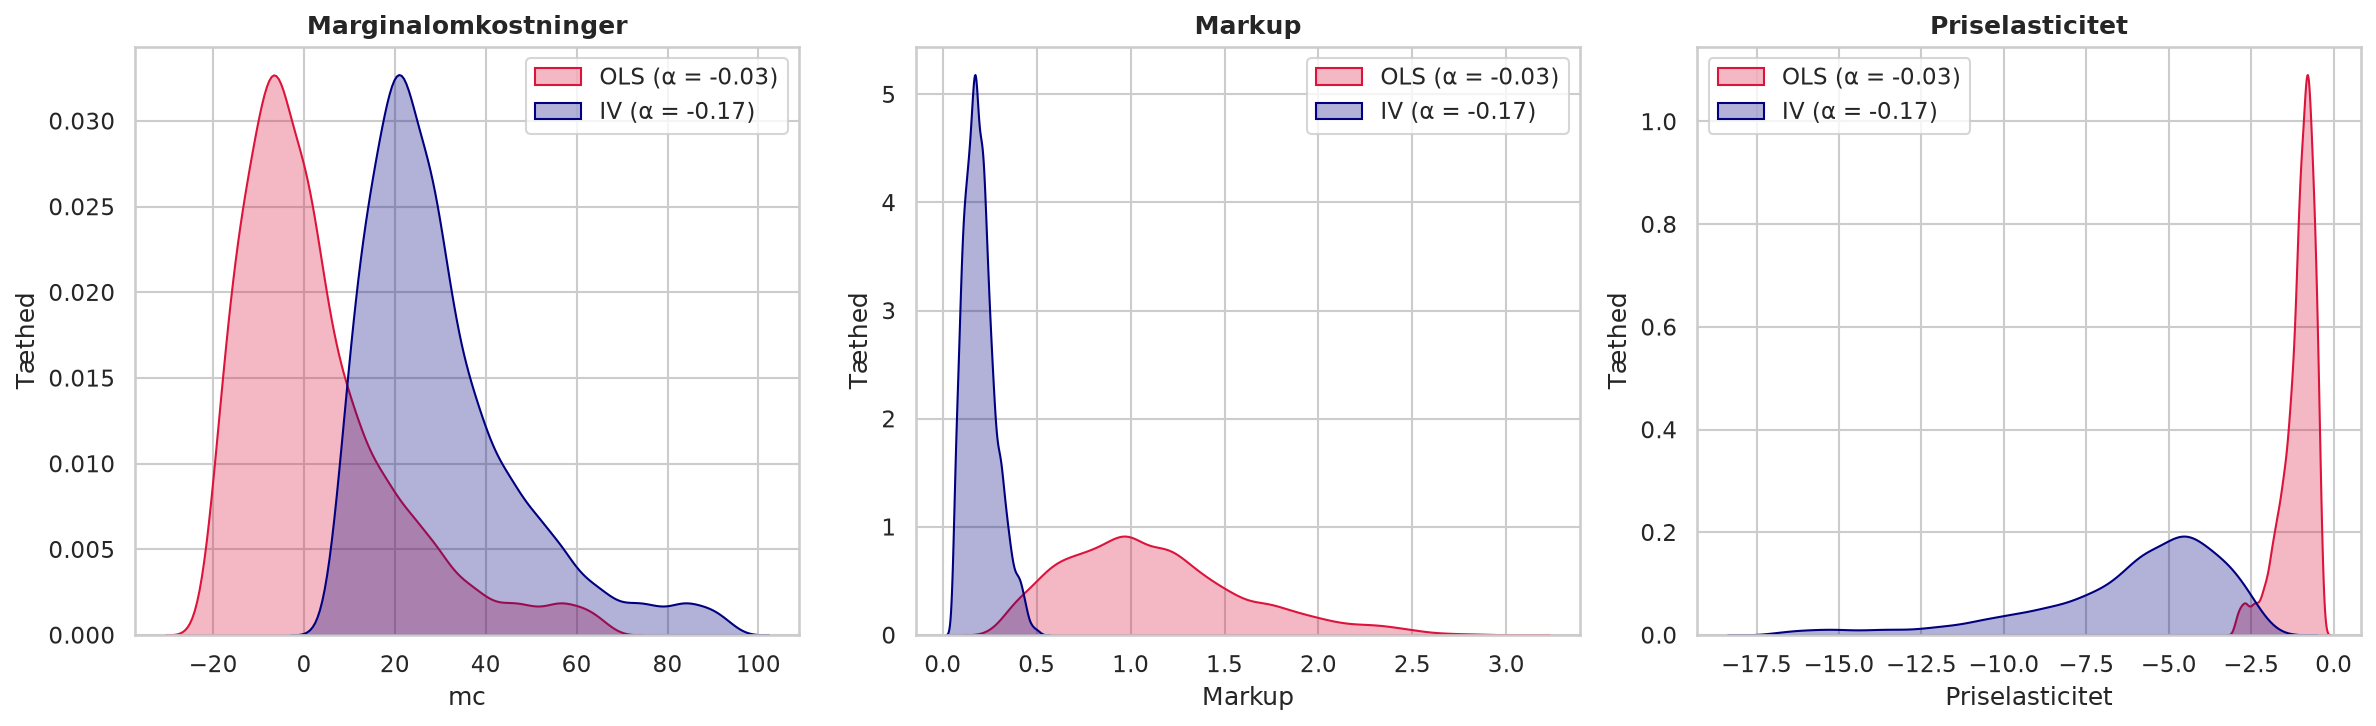

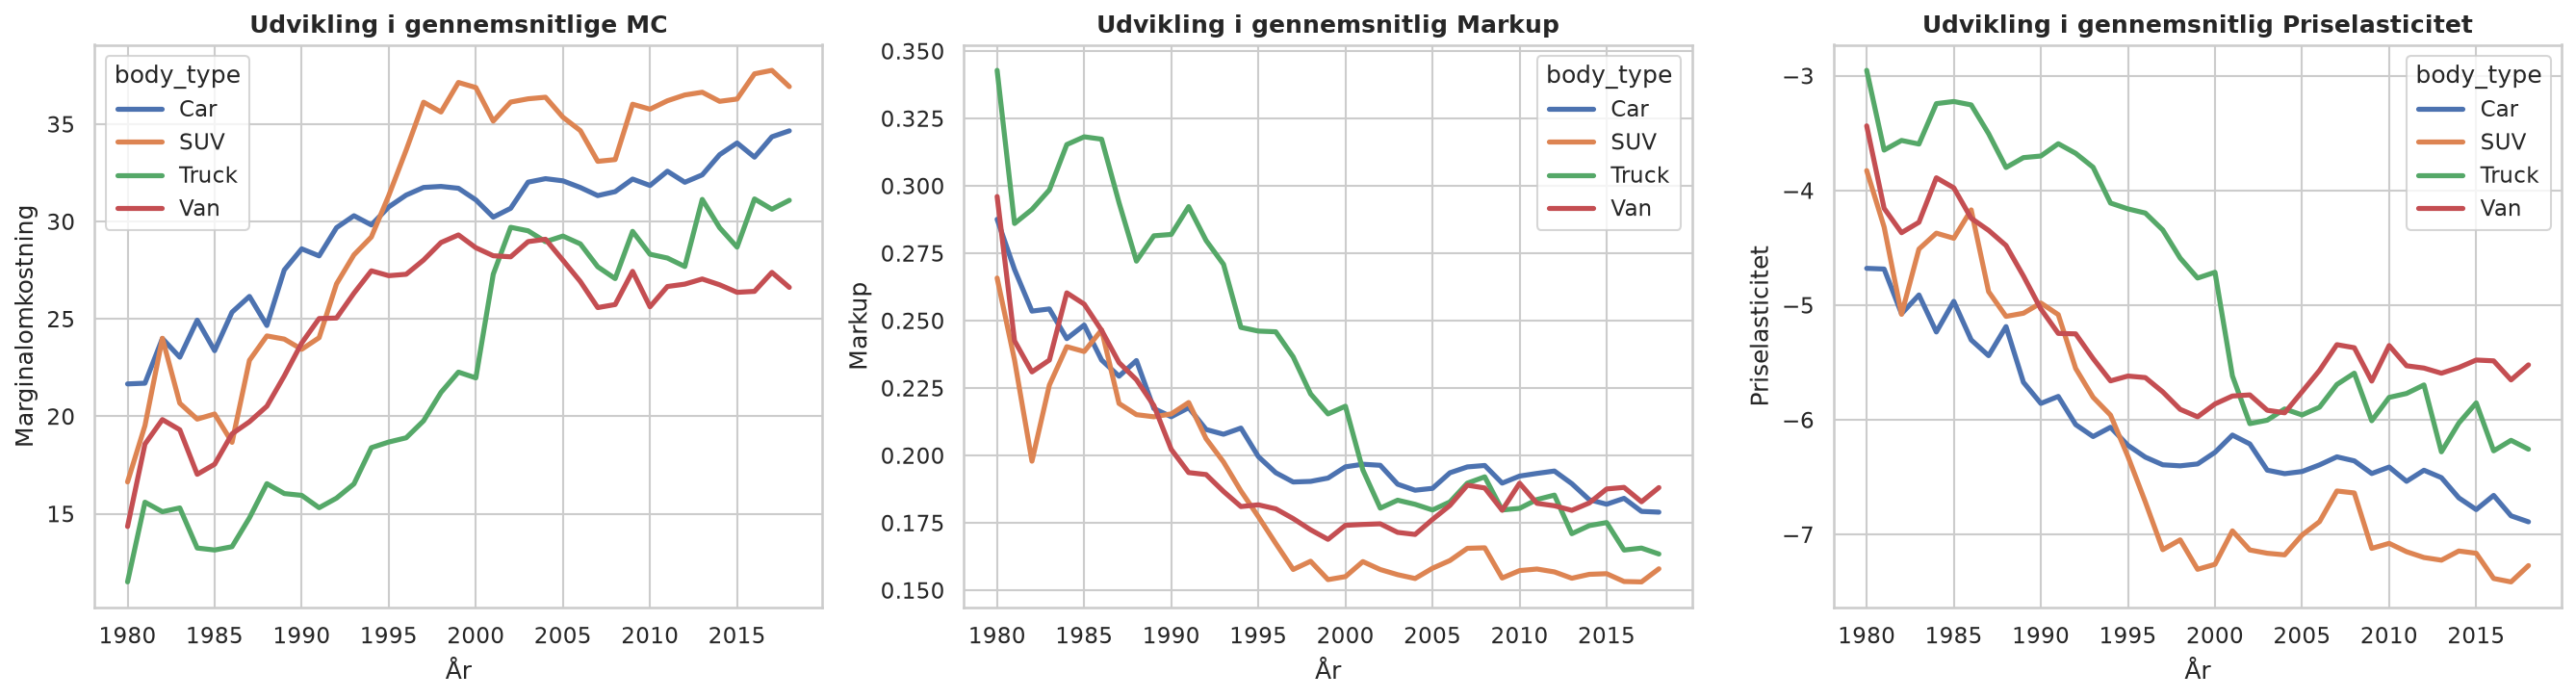

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cars.csv')

alpha_ols = -0.03
alpha_iv = -0.17

df['mc_ols'] = df['price'] - 1.0 / (-alpha_ols * (1.0 - df['market_share']))
df['mc_iv'] = df['price'] - 1.0 / (-alpha_iv * (1.0 - df['market_share']))

df['elasticity_ols'] = alpha_ols * df['price'] * (1.0 - df['market_share'])
df['elasticity_iv'] = alpha_iv * df['price'] * (1.0 - df['market_share'])

df['markup_ols'] = (df['price'] - df['mc_ols']) / df['price']
df['markup_iv'] = (df['price'] - df['mc_iv']) / df['price']

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def get_body_type(row):
    if row['car'] == 1: return 'Car'
    if row['suv'] == 1: return 'SUV'
    if row['truck'] == 1: return 'Truck'
    if row['van'] == 1: return 'Van'
    return 'Other'

df['body_type'] = df.apply(get_body_type, axis=1)

df_body = df[df['body_type'].isin(['Car', 'SUV', 'Truck', 'Van'])].copy()

yearly_body = df_body.groupby(['year', 'body_type'])[['mc_iv', 'markup_iv', 'elasticity_iv']].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.kdeplot(df['mc_ols'], ax=axes[0], label='OLS (α = -0.03)', color='crimson', fill=True, alpha=0.3)
sns.kdeplot(df['mc_iv'], ax=axes[0], label='IV (α = -0.17)', color='navy', fill=True, alpha=0.3)
axes[0].set_title('Marginalomkostninger', fontsize=12, fontweight='bold')
axes[0].set_xlabel('mc')
axes[0].set_ylabel('Tæthed')
axes[0].legend()

sns.kdeplot(df['markup_ols'], ax=axes[1], label='OLS (α = -0.03)', color='crimson', fill=True, alpha=0.3)
sns.kdeplot(df['markup_iv'], ax=axes[1], label='IV (α = -0.17)', color='navy', fill=True, alpha=0.3)
axes[1].set_title('Markup', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Markup')
axes[1].set_ylabel('Tæthed')
axes[1].legend()

sns.kdeplot(df['elasticity_ols'], ax=axes[2], label='OLS (α = -0.03)', color='crimson', fill=True, alpha=0.3)
sns.kdeplot(df['elasticity_iv'], ax=axes[2], label='IV (α = -0.17)', color='navy', fill=True, alpha=0.3)
axes[2].set_title('Priselasticitet', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Priselasticitet')
axes[2].set_ylabel('Tæthed')
axes[2].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=yearly_body, x='year', y='mc_iv', hue='body_type', ax=axes[0], linewidth=2.5)
axes[0].set_title('Udvikling i gennemsnitlige MC', fontsize=12, fontweight='bold')
axes[0].set_xlabel('År')
axes[0].set_ylabel('Marginalomkostning')

sns.lineplot(data=yearly_body, x='year', y='markup_iv', hue='body_type', ax=axes[1], linewidth=2.5)
axes[1].set_title('Udvikling i gennemsnitlig Markup', fontsize=12, fontweight='bold')
axes[1].set_xlabel('År')
axes[1].set_ylabel('Markup')

sns.lineplot(data=yearly_body, x='year', y='elasticity_iv', hue='body_type', ax=axes[2], linewidth=2.5)
axes[2].set_title('Udvikling i gennemsnitlig Priselasticitet', fontsize=12, fontweight='bold')
axes[2].set_xlabel('År')
axes[2].set_ylabel('Priselasticitet')

plt.tight_layout()
plt.show()

## 3C

In [10]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df = pd.read_csv('cars.csv')

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

chars4 = [
    'log_hp',
    'log_mpg',
    'log_height',
    'log_footprint',
    'log_weight',
    'log_number_trims',
    'releaseYear',
    'yearsSinceDesign',
    'sport',
    'EV',
    'truck',
    'suv',
    'van',
]

year_dummies = pd.get_dummies(
    df['year'], prefix='y', drop_first=True, dtype=float
)
make_dummies = pd.get_dummies(
    df['make'], prefix='make', drop_first=True, dtype=float
)

df['mc_iv_est'] = df['price'] - 1.0 / (-0.17 * (1.0 - df['market_share']))

df['log_mc_est'] = np.log(df['mc_iv_est'])

chars_str = ' + '.join(chars4)

formula_3c_est = f'log_mc_est ~ RXR + {chars_str} + make_dummies + year_dummies'

reg_3c_est = smf.ols(formula_3c_est, data=df).fit()

main_vars = ['RXR'] + chars4

res_df = pd.DataFrame({
    'Coef': reg_3c_est.params[main_vars],
    'Std.Err': reg_3c_est.bse[main_vars],
    't-stat': reg_3c_est.tvalues[main_vars],
    'p-val': reg_3c_est.pvalues[main_vars]
})

print(res_df.to_string())

                      Coef   Std.Err     t-stat          p-val
RXR               0.112701  0.009216  12.228461   3.932901e-34
log_hp            0.342851  0.009473  36.194342  5.523650e-269
log_mpg           0.097320  0.010913   8.917504   5.642866e-19
log_height       -0.462789  0.026572 -17.416135   6.638367e-67
log_footprint    -0.141134  0.023835  -5.921400   3.301889e-09
log_weight        0.882478  0.020257  43.563716   0.000000e+00
log_number_trims -0.023589  0.001805 -13.065886   1.103425e-38
releaseYear      -0.011682  0.005237  -2.230630   2.572869e-02
yearsSinceDesign -0.000551  0.000498  -1.105263   2.690734e-01
sport             0.105566  0.005452  19.362188   5.852910e-82
EV                0.206524  0.017474  11.819191   5.181523e-32
truck            -0.099123  0.007079 -14.001691   4.135815e-44
suv              -0.001954  0.005627  -0.347330   7.283512e-01
van              -0.022931  0.008063  -2.844099   4.463153e-03
